# Evaluation analysis

Reads the saved runs in `evaluation/runs/` (no model or database needed) and looks at where the
copilot succeeds and fails. Each run file has one record per golden question, including the
SQL the model produced.

In [1]:
import json, math
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RUNS = Path("../evaluation/runs")
def load(label):
    return pd.DataFrame([json.loads(x) for x in (RUNS / f"{label}.jsonl").read_text().splitlines()])

runs = {label: load(label) for label in
        ["all-v4", "all-v4-noretrieval", "all-v4-nocorrect", "all-v4-3b"]}
sql = {k: v[v.kind == "sql"] for k, v in runs.items()}
{k: f"{v.correct.sum()}/{len(v)}" for k, v in sql.items()}

{'all-v4': '49/56',
 'all-v4-noretrieval': '49/56',
 'all-v4-nocorrect': '48/56',
 'all-v4-3b': '32/56'}

## Accuracy with 95% intervals

With 56 questions, one question is ~1.8 points. The Wilson interval shows how much of each
difference could be noise.

,config,accuracy,lo,hi
0,7B full,0.875,0.764,0.938
1,"7B, no retrieval",0.875,0.764,0.938
2,"7B, no correction",0.857,0.743,0.926
3,3B full,0.571,0.441,0.692


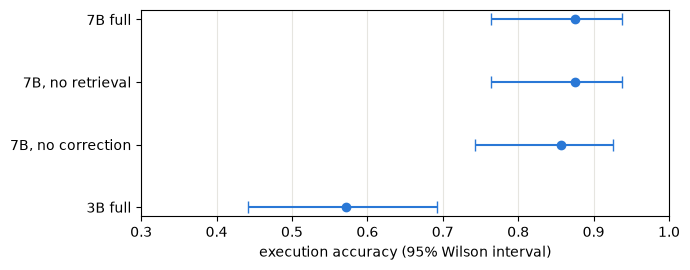

In [2]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z*z/(2*n)) / (1 + z*z/n)
    h = z * math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

names = {"all-v4": "7B full", "all-v4-noretrieval": "7B, no retrieval",
         "all-v4-nocorrect": "7B, no correction", "all-v4-3b": "3B full"}
rows = []
for k, v in sql.items():
    lo, hi = wilson(v.correct.sum(), len(v))
    rows.append((names[k], v.correct.mean(), lo, hi))
df = pd.DataFrame(rows, columns=["config", "accuracy", "lo", "hi"])
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.errorbar(df.accuracy, df.config, xerr=[df.accuracy - df.lo, df.hi - df.accuracy],
            fmt="o", color="#2a78d6", capsize=4)
ax.set_xlim(0.3, 1.0); ax.set_xlabel("execution accuracy (95% Wilson interval)")
ax.invert_yaxis(); ax.grid(axis="x", color="#e6e5e0"); plt.tight_layout()
df.round(3)

## Accuracy by question category

In [3]:
by_cat = pd.DataFrame({names[k]: v.groupby("category").correct.mean() for k, v in sql.items()})
by_cat["n"] = sql["all-v4"].groupby("category").size()
by_cat.round(2)

,7B full,"7B, no retrieval","7B, no correction",3B full,n
category,,,,,
advanced,0.56,0.67,0.44,0.11,9
aggregate,0.90,0.90,0.90,0.90,10
breakdown,0.90,0.90,0.90,0.60,10
comparison,0.80,0.80,0.80,0.20,5
ranking,1.00,1.00,1.00,0.57,7
relative_time,1.00,0.88,1.00,0.75,8
trend,1.00,1.00,1.00,0.71,7


## Prompt size: what schema retrieval saves

In [4]:
pd.DataFrame({
    "mean prompt tokens": {names[k]: v.prompt_tokens.mean() for k, v in sql.items()},
    "mean tables in prompt": {names[k]: v.tables_selected.mean() for k, v in sql.items()},
}).round(1)

,mean prompt tokens,mean tables in prompt
7B full,1593.5,2.4
"7B, no retrieval",2892.7,8.0
"7B, no correction",1355.7,2.4
3B full,1907.0,2.4


## Does the 3B model fail on the same questions as 7B?

In [5]:
both = sql["all-v4"][["id", "category", "correct"]].merge(
    sql["all-v4-3b"][["id", "correct"]], on="id", suffixes=("_7b", "_3b"))
pd.crosstab(both.correct_7b, both.correct_3b, rownames=["7B correct"], colnames=["3B correct"])

3B correct,False,True
7B correct,,
False,7,0
True,17,32


If the smaller model were right on questions the larger one misses, combining them
could help. The cross-tab shows whether the 3B failures are simply a superset.

## What the self-correction loop actually changed

In [6]:
full = sql["all-v4"]
corrected = full[full.attempts > 1][["id", "attempts", "correct", "first_attempt_correct", "error"]]
corrected

,id,attempts,correct,first_attempt_correct,error
45,q46,2,False,False,NaN
47,q48,2,True,False,NaN
51,q52,2,False,False,NaN
52,q53,3,False,False,"sql_error: column reference ""order_item_id"" is..."
53,q54,2,False,False,NaN
54,q55,2,False,False,NaN


## Remaining failures of the full pipeline

In [7]:
pd.set_option("display.max_colwidth", 120)
full[~full.correct][["id", "category", "question"]]

,id,category,question
6,q07,aggregate,"How many stores do we have in California, not counting online?"
24,q25,breakdown,What was revenue by region for physical stores in 2025?
45,q46,comparison,How did Camping revenue in California compare between August and September 2026?
51,q52,advanced,"For each month of 2026, what was revenue and the percent change from the previous month?"
52,q53,advanced,What was the return rate of the Granite Peak Summit Down Jacket for orders placed March through May 2026? Use return...
53,q54,advanced,What was the average number of items (order lines) per completed order in 2025?
54,q55,advanced,What was revenue per dollar of marketing spend in each state in 2025?
